# Quantcore design loop: lay out → KLayout → LOM → HFSS → extract → Hamiltonian → feedback

There are three ways into the loop, and all of them produce the same `design.json` and the same lumped circuit:

1. **Code (this notebook):** lay the chip out in Python. KLayout draws each component as you add it.
2. **KLayout plugin:** place components from the Quantcore panel, connect them with *Connect* or
   *Route handles*, then use *Export LOM circuit* to get a netlist you can simulate later
   (`examples/lom_from_layout.ipynb`).
3. **LOM first:** start from qubit and resonator targets and let `qcc` synthesise the layout
   (`qcc circuit layout`, or the last section of `lom_from_layout.ipynb`).

Every component carries a **LOM model** whose nodes map to its ports:

- a transmon is an island node with C and a JJ/SQUID to ground, and its claw is a coupler node;
- a meander ending in a hanger is a λ/4 resonator plus a coupled-line κ to the feedline;
- a bond pad is a 50 Ω port.

The layout's connectivity is therefore also the circuit's netlist. Before a simulation the element values are
component estimates; after HFSS/Q3D they come from the C-matrix.

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
os.chdir(ROOT)                                   # paths below are relative to the repo root

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import quantcore_circuits as qcc
from quantcore_circuits import loop, plots
from quantcore_circuits.designer import Designer
from quantcore_circuits.live.snapshot import gui_snapshot, snapshot
from quantcore_circuits.track import Run

usetex = plots.use_style()                       # plot-guidelines style
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
KLAYOUT_GUI = True                               # True: open / raise the KLayout window; False: redraw an open one only
from quantcore_circuits.live.klayout import use_gui
use_gui(KLAYOUT_GUI)
from quantcore_circuits import track
TRACKING = track.start()                         # dashboard: build/<design> (shared with run = Run(DESIGN))


def shot(png, size, layout, box=None):          # KLayout GUI screenshot when live, else headless render
    if LIVE:
        return gui_snapshot(png, size, layout=layout, box=box)
    return snapshot(layout, png, size=size, box=box), "headless"

### The FEM part in two stages, and its switches

As in the tutorials, the FEM part runs in two stages: (1) a **subset check**, FEM only (did the job converge, are the
C-matrix values sane?), then (2) **the whole LOM**: render the chip, fill the netlist, simulate (Hamiltonian, consensus),
compare, feed back. No LOM is simulated on a subset and nothing is fed back from it. **`SIM_SUBSET`** says which part
of the chip goes into the stage-1 Q3D: `[("Q1", "R1")]` (the qubit, its λ/4 and the feedline next to it, which the box
cuts into 50 Ω ports: the sim group `Q1R1` — this chip has one pair, so it is the chip minus its pads and stage 2 reuses
it) or, with `FEM_WHOLE = True` (opt-in), `"whole"` (the whole chip with its pads, the built-in group `chip`). **`RUN_FEM = True`** renders the whole chip
into HFSS (section 5) and solves the Q3D job (section 6) in AEDT; `False` starts no AEDT and reads the kept results.
`FEM_FAST` uses the fast test settings; `AEDT_MODE` picks how AEDT runs (section 5).

In [ ]:
SIM_SUBSET = [("Q1", "R1")]      # (qubit, readout) pairs to render and simulate, or "whole" (the chip with its pads)
FEM_WHOLE = False                # True (opt-in, slower): the whole chip with its pads instead of the subset
if FEM_WHOLE:
    SIM_SUBSET = "whole"
RUN_FEM = False                  # True: render the whole chip and solve the SIM_SUBSET Q3D job in AEDT; False: no AEDT
FEM_FAST = True                  # True: fast test settings (Q3D 2 %, ≤ 8 passes); False: the defaults
AEDT_MODE = "batch"              # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

## 1 · Lay out the chip (one cell, live in KLayout)

`Designer(live=True)` starts KLayout if it isn't open (with the Quantcore plugin loaded from the repo), then
rebuilds and reloads after every `add` / `route`. Ports are attributes (`q1.claw_n`). A route must name ports that
are placed already (place first, then route). Unknown cells, parameters or ports raise immediately, with the valid names listed.

In [2]:
d = Designer("q1_r1_code", box=(0, 0, 7500, 7500), chip={"name_chip": "Q1R1"}, live=LIVE, delay=0.4)

# ports: bond pads on the chip edge
pad_w = d.add("PAD_W", "BondPad", at=(1125, 3750), rot=270)
pad_e = d.add("PAD_E", "BondPad", at=(6375, 3750), rot=90)
# feedline
fl = d.route("FL", pad_w.a, pad_e.a, airbridges="none")
# qubit (Xmon) with its trilayer SQUID junction (Lj, Cj feed the simulation and the LOM)
q1 = d.add("Q1", "Xmon", at=(2975, 2200), cross_length=300, arm_width=25, gap=25, claws=["n"],
           flux_port=True, junction_type="Trilayer Squid", junction={"Lj_nH": 12.0, "Cj_fF": 2.0})
# readout: λ/4 meander from the claw, hanging off the feedline (coupler 300 µm, shorted end)
r1 = d.route("R1", q1.claw_n, fl.hanger(s=2000, length=300, side="right"), meander=4200)
# flux bias: pad + CPW tapering into the qubit's flux port
pad_f = d.add("PAD_F", "BondPad", at=(2964.5, 750), a=4, b=6, pad_width=300, pad_height=300, pad_gap=150,
              taper_length=300)
d.route("FLUX", pad_f.a, q1.flux, a=4, b=6, nodes=[d.waypoint((2964.5, 1967.0), a=1, b=7.5)])

d.targets(Q1={"f_q_GHz": 5.1, "alpha_MHz": -220}, R1={"f_GHz": 7.2, "g_MHz": 90})
# SIM_SUBSET → the sim group: [("Q1", "R1")] is "Q1R1" (Q1 + R1 + 300 µm); "whole" → the built-in "chip"
SIM_GROUP = ("chip" if SIM_SUBSET == "whole" else
             d.sim_subset("Q1R1", pairs=SIM_SUBSET, margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])[0])
if not LIVE:
    d.show()                                     # build + write build/q1_r1_code.oas (no KLayout)
DESIGN = d.save("examples/q1_r1_code.json")
print(d, "→", DESIGN, "| R1", round(r1.length, 2), "µm")

[qcc] add PAD_W (BondPad): built in 0.18 s → build\q1_r1_code.oas


[qcc] add PAD_E (BondPad): built in 0.11 s → build\q1_r1_code.oas


[qcc] route FL: built in 0.11 s → build\q1_r1_code.oas


[qcc] add Q1 (Xmon): built in 0.10 s → build\q1_r1_code.oas


[qcc] route R1: built in 0.16 s → build\q1_r1_code.oas


[qcc] add PAD_F (BondPad): built in 0.11 s → build\q1_r1_code.oas


[qcc] route FLUX: built in 0.17 s → build\q1_r1_code.oas


<Designer q1_r1_code: 4 instances, 3 routes, live=True> → examples\q1_r1_code.json | R1 4200.0 µm


## 2 · Connect the dashboard

The dashboard tracks this run (`build/q1_r1_code/state.json`) and updates live. Run the next cell to connect, and
the one at the end of the notebook to disconnect.

In [3]:
run = Run(DESIGN, reset=True)
dash = qcc.review.connect(DESIGN)     # http://127.0.0.1:8765 — parameters, plots, circuit, Hamiltonian, steps
dash

qcc dashboard: http://127.0.0.1:8765/  (design q1_r1_code, run dir build\q1_r1_code)


<Dashboard http://127.0.0.1:8765/ running>

## 3 · Layout → LOM netlist, DRC, screenshots

The DRC checks that every pin, endpoint and handle is connected, that nothing sits outside the chip, that nothing
overlaps or crosses, and that the declared netlist matches the geometry.

DRC clean


| element | type | nodes | estimate |
|---|---|---|---|
| Port_PAD_W | R | FL – gnd | 50 |
| Port_PAD_E | R | FL – gnd | 50 |
| C_Q1 | C | Q1 – gnd | 64.05 |
| J_Q1 | SQUID | Q1 – gnd | 12 |
| Cg_Q1_claw_n | C | Q1 – Q1.claw_n | 3.17 |
| Cc_Q1_claw_n | C | Q1.claw_n – gnd | 76.4 |
| R1 | TLres | Q1.claw_n – gnd | 7.62 |
| K_R1 | HANGER | Q1.claw_n – FL | 0.2189 |

controls: {'FLUX': {'kind': 'flux_bias', 'target': 'J_Q1', 'line': 'FLUX', 'length_um': 1359.5}}


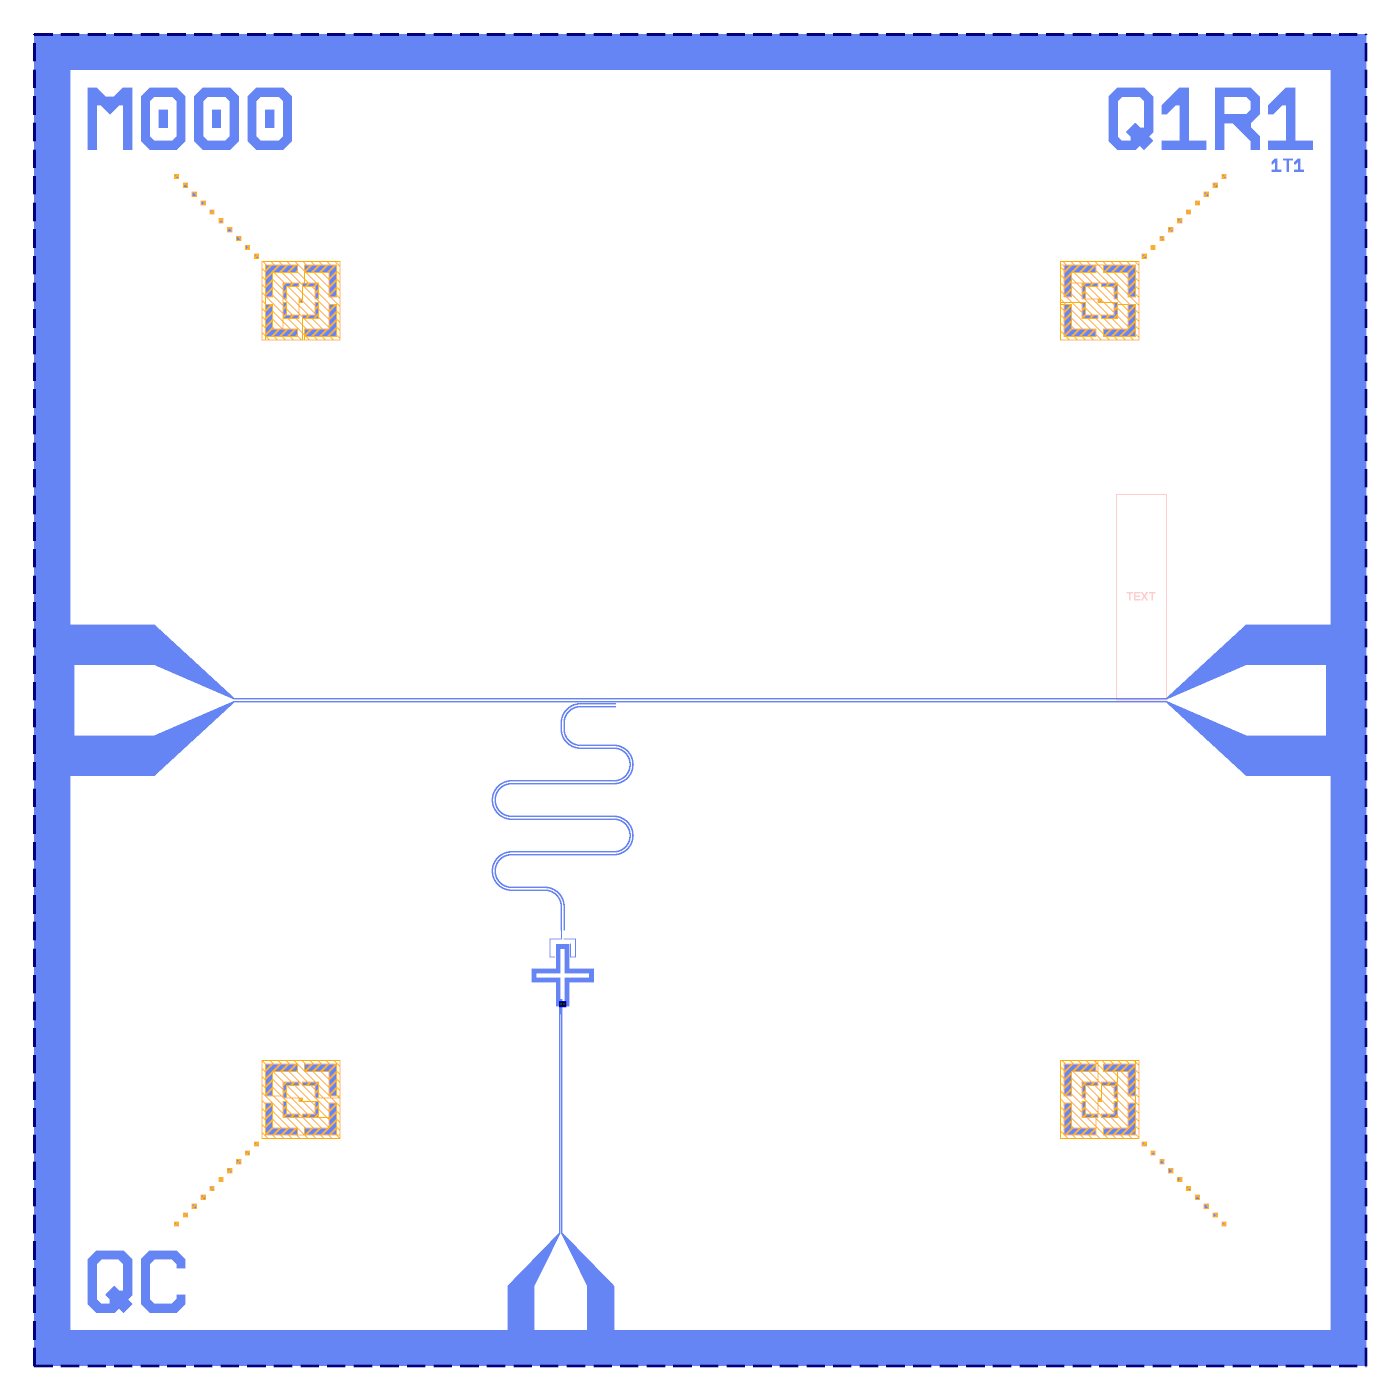

In [4]:
from quantcore_circuits.analysis.synthesis import synthesize_transmon_readout
run.start("synthesis")
syn = synthesize_transmon_readout(5.1, -220, 7.2, 90)
run.done("synthesis", f"Lj {syn['Lj_nH']:.2f} nH · C_Σ {syn['C_sigma_fF']:.1f} fF · C_g {syn['Cg_fF']:.2f} fF · "
         f"λ/4 {syn['resonator_length_um']:.0f} µm")
run.start("layout")
drc = d.drc()
lom = d.lom()
print(drc)
display(Markdown("| element | type | nodes | estimate |\n|---|---|---|---|\n" + "\n".join(
    f"| {n} | {b.type} | {b.nodes[0]} – {b.nodes[1]} | "
    + (f"{b.value.get('estimate', b.value.get('Lj_nH', b.value.get('kappa_MHz', b.value.get('R_ohm', b.value.get('f_GHz'))))):.4g}"
       if any(k in b.value for k in ('estimate', 'Lj_nH', 'kappa_MHz', 'R_ohm', 'f_GHz')) else "–") + " |"
    for n, b in lom.model.branches.items())))
print("controls:", lom.model.controls)
for ident, title, box in (("chip", "Chip", None), ("q1", "Q1 close-up", (2550, 1750, 3450, 2850))):
    png, src = shot(run.dir / "shots" / f"{ident}.png", (1400, 1400 if box is None else 1200), d.out, box)
    run.screenshot(png, title, "layout", f"KLayout {src}", src, ident)
run.done("layout", f"DRC {'clean' if drc.ok else 'ERRORS'} · " + " · ".join(f"{k} {v:.1f} µm" for k, v in d.result.route_lengths().items()))
display(Image(filename=str(run.dir / "shots" / "chip.png"), width=480))

## 4 · LOM simulation straight from the layout (no FEM yet)

The circuit above has component-estimate values. QuCat finds the normal modes and κ through the 50 Ω pads, and
QuTiP diagonalises the circuit Hamiltonian.

In [5]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate
lom_sim = simulate(fill(lom.model, DESIGN))
display(Markdown("| mode | kind | f (GHz) | κ (MHz) | A (MHz) |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {m.label} | {m.kind} | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.anharmonicity_MHz:.1f} |" for m in lom_sim.modes)))
print({k: round(v, 4) for k, v in lom_sim.params.items()})

| mode | kind | f (GHz) | κ (MHz) | A (MHz) |
|---|---|---|---|---|
| Q1 | qubit | 5.5201 | 0.000137 | 278.4 |
| R1 | resonator | 6.7600 | 0.135 | 0.0 |

{'Q1.f_q_GHz': 5.2243, 'Q1.alpha_MHz': -321.0169, 'R1.chi_MHz': -0.9612, 'R1.f_GHz': 6.7594, 'R1.kappa_MHz': 0.1353}


## 5 · Render the whole chip into HFSS (stage 2, AEDT 2024 R2)

With `RUN_FEM = True` the whole chip goes in, with an Lj RLC on the junction and 50 Ω ports on the pads. With `RUN_FEM = False` (or without AEDT) the
job is only exported and no AEDT is started.

**`AEDT_MODE`**: `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

In [6]:
from quantcore_circuits.sim_tools import hfss, build_simulation, export_job
from quantcore_circuits.sim_tools.ansys import find_ansys_executable
from quantcore_circuits.sim_tools.export import set_fem_fast
set_fem_fast(FEM_FAST)                           # RUN_FEM, FEM_FAST, AEDT_MODE: the SIM_SUBSET cell
run.start("render")
if RUN_FEM and find_ansys_executable():
    r = hfss.render(DESIGN, "chip", "hfss_eigenmode", aedt=AEDT_MODE)
    (run.done if r.ok else run.fail)("render", f"{r.project} ({r.seconds:.0f} s)")
else:
    setup = build_simulation(DESIGN, "chip", "hfss_eigenmode")
    job = export_job(setup, Path("build/jobs") / setup.simulation.name, overwrite=True)
    run.skip("render", f"{'RUN_FEM = False' if find_ansys_executable() else 'AEDT 2024 R2 not installed'}; "
                       f"exported {job.name}")
    print("exported", job, [(p.number, p.kind, p.name) for p in setup.ports])
run.refresh_jobs()

exported build\jobs\q1_r1_code_chip_hfss_eigenmode [(1, 'junction', 'Q1.junction'), (2, 'lumped', 'PAD_W.pad'), (3, 'lumped', 'PAD_E.pad'), (4, 'lumped', 'PAD_F.pad')]


[{'name': 'q1_r1_code_chip_hfss_eigenmode',
  'group': 'chip',
  'analysis': 'hfss_eigenmode',
  'solver': 'ansys',
  'status': 'exported',
  'created': '2026-11-02T21:53:19+00:00',
  'finished': None,
  'hasResults': False,
  'project': None}]

## 6 · FEM: the subset check (stage 1), then LOM builder → Hamiltonian → compare (stage 2)

The Q1R1 Q3D job (solved earlier on silicon, rescaled to sapphire until it is re-run) replaces the capacitance
estimates. Then four estimators and a QuTiP solve run, with a simulated readout for χ, followed by the consensus
against the targets.

note: stack correction: job simulated with εr=11.45, design PDK εr=10.25; capacitances × 0.9036 ((ε+1)/2 scaling) until the job is re-run on quantcore_nb_sapphire_v1
note: Q1.claw_n: removed 14.39 fF of the 100 µm port stub (counted in the λ/4 line)


| branch | estimate | FEM | chosen | design |
|---|---|---|---|---|
| C_Q1 | 64.05 | 64.05 | 64.05 | 89.97 |
| J_Q1 | 12 | – | 12 | 9.259 |
| Cg_Q1_claw_n | 3.17 | 3.173 | 3.173 | 5.132 |
| Cc_Q1_claw_n | 76.4 | 76.41 | 76.41 | – |
| R1 | 4200 | – | 4200 | 4445 |
| Port_FL | 25 | – | 25 | 25 |
| K_R1 | 0.2189 | – | 0.2189 | – |

# Consensus

| parameter | metal_lom | qucat | qutip | scqubits | sqcircuit | chosen | spread | target | residual/tol | status |
|---|---|---|---|---|---|---|---|---|---|---|
| Q1.EC_GHz (GHz) | 0.2803 | 0.2799 | – | 0.2799 | 0.2799 | **0.2803** (metal_lom) | 0.14 % | – | – | unknown |
| Q1.EJ_GHz (GHz) | 13.62 | 13.62 | – | 13.62 | 13.62 | **13.62** (metal_lom) | 0.00 % | – | – | unknown |
| Q1.alpha_MHz (MHz) | -321.9 | -321 | -321.5 | -321.5 | -321.5 | **-321.5** (sqcircuit) | 0.29 % | -220 ± 10 | -10.15 | fail |
| Q1.f_q_GHz (GHz) | 5.228 | 5.224 | 5.224 | 5.224 | 5.224 | **5.224** (sqcircuit) | 0.07 % | 5.1 ± 0.02 | +6.21 | fail |
| R1.chi_MHz (MHz) | -1.038 | -0.9487 | -0.9491 | -1.003 | -0.9491 | **-0.9487** (qucat) | 9.15 % | – | – | unknown |
| R1.f_GHz (GHz) | 6.783 | 6.783 | 6.783 | 6.783 | 6.783 | **6.783** (qucat) | 0.00 % | 7.2 ± 0.01 | -41.70 | fail |
| R1.g_MHz (MHz) | 56.13 | – | 58.07 | 59.71 | – | **56.13** (metal_lom) | 6.17 % | 90 ± 10 | -3.39 | fail |


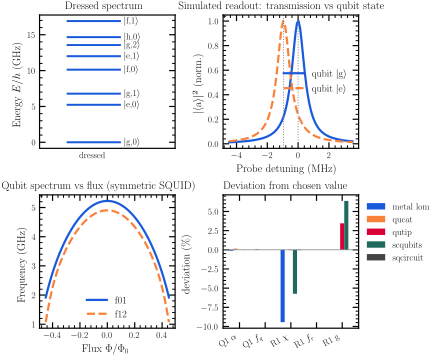

In [7]:
OWN_Q3D = Path(f"build/jobs/q1_r1_code_{SIM_GROUP}_q3d_cmatrix")   # this design's own Q3D job (SIM_SUBSET)
run.start("simulate")
if RUN_FEM and find_ansys_executable():
    r = hfss.render(DESIGN, SIM_GROUP, "q3d_cmatrix", job_dir=OWN_Q3D, solve=True, aedt=AEDT_MODE, timeout=1800)
    print("Q3D", "ok" if r.ok else "FAILED", f"in {r.seconds:.0f} s (AEDT {r.mode} pid {r.pid})")
if (OWN_Q3D / "results" / "results.json").exists():   # solved (now or earlier): read it back from the job
    JOB_Q3D = OWN_Q3D
    run.done("simulate", f"Q3D C-matrix {SIM_GROUP} ({OWN_Q3D.name})")
else:                                            # not solved yet: the Q1R1 job solved for q1_r1_feedline
    JOB_Q3D = "build/jobs/q1_r1_feedline_Q1R1_q3d_cmatrix"
    run.done("simulate", "Q3D C-matrix Q1R1 (existing job of q1_r1_feedline)")
run.refresh_jobs()
# stage 1, the subset check (FEM only): did the Q3D converge, which nets came back?
res_q3d = json.loads((Path(JOB_Q3D) / "results" / "results.json").read_text(encoding="utf-8"))
conv = res_q3d.get("convergence") or {}
print(f"subset check: {Path(JOB_Q3D).name}: {len(conv.get('passes') or [])} passes, converged {conv.get('converged')}, "
      f"nets {res_q3d['cmatrix']['labels']}, diagonal (fF) {[round(r[i], 2) for i, r in enumerate(res_q3d['cmatrix']['matrix'])]}")
# stage 2: the netlist filled from the job (the box is the chip minus its pads) → estimators, Hamiltonian, consensus
an = loop.analyse(DESIGN, JOB_Q3D, run=run, kappa_MHz=None, out_dir=run.dir)
for note in an.filled.notes:
    print("note:", note)
display(Markdown("| branch | estimate | FEM | chosen | design |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {r['branch']} | " + " | ".join(f"{x:.4g}" if isinstance(x, (int, float)) else "–"
                                        for x in (r['estimate'], r['extracted'], r['value'], r['design'])) + " |"
    for r in an.filled.branch_table())))
from quantcore_circuits.circuit.consensus import report_markdown
display(Markdown(report_markdown(an.rows, "Consensus")))
spec = {p["id"]: p for p in an.plots}
fig, axes = plots.figure("grid2x2", 2, 2)
for ax, key in zip(axes.flat, ("levels", "readout", "flux", "estimator_spread")):
    plots.plot_spec(spec[key], ax)
plots.save(fig, run.dir / "figures" / "hamiltonian"); plt.show()

## 7 · Feedback: new knobs → revision → shown live in KLayout

| knob | now | proposed |
|---|---|---|
| `Q1.cross_length` | 300 | **416.73** |
| `Q1.claw_length` | 100 | **182.153** |
| `Q1.junction.Lj_nH` | 12 | **9.282** |
| `R1.length` | 4200 | **3640.92** |

[qcc] build: built in 0.11 s → build\q1_r1_code.oas


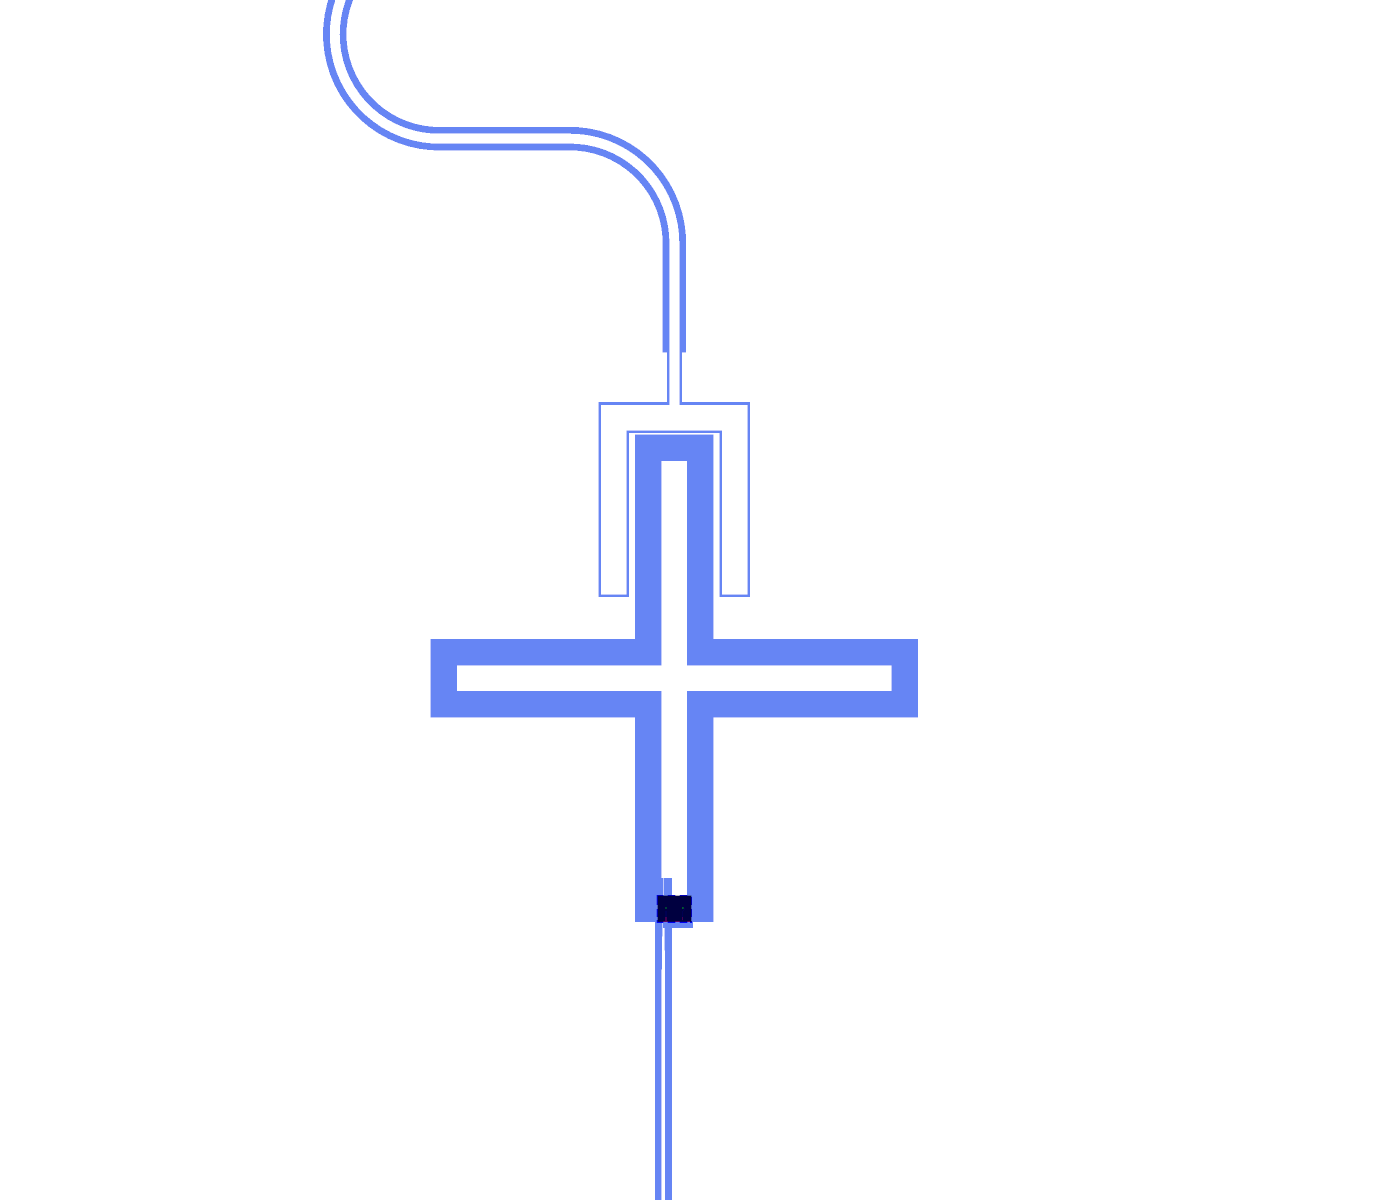

{"reached": false, "passed": 0, "total": 4, "summary": "0 of 4 targets within tolerance"}


In [8]:
prop, rev, rev_result = loop.feedback(an, run, DESIGN)
display(Markdown("| knob | now | proposed |\n|---|---|---|\n" + "\n".join(
    f"| `{k}` | {prop.start_knobs[k]:g} | **{v:g}** |" for k, v in prop.knobs.items())))
d1 = Designer.load(rev, live=LIVE)               # the revision, drawn in KLayout
if not LIVE:
    d1.show()
png, src = shot(run.dir / "shots" / "q1_rev1.png", (1400, 1200), d1.out, (2550, 1700, 3450, 2850))
run.screenshot(png, "Q1 — revision 1 (proposed)", "feedback", "surrogate prediction; simulate to confirm", src, "q1_rev1")
display(Image(filename=str(png), width=420))
print(json.dumps(run.state["goal"]))

## Disconnect the dashboard

In [9]:
dash.disconnect()
dash

<Dashboard http://127.0.0.1:8765/ stopped>